## Problem description

A bike sharing operator needs to know how many bikes will be in use at each hour to decide how many to keep at the stations and when to rebalance or service them. Too few bikes leave riders without service, and too many leave idle bikes and wasted logistics.

**Business question:** How many bikes will be rented in a given hour, given the calendar and weather conditions?

**Dataset:** Bike Sharing, hourly file (UCI #275). It has 17,379 hourly records from the Capital Bikeshare system in Washington, D.C., covering 2011 and 2012, with calendar, weather and rental counts.

**Target:** `cnt`, the total number of rentals in the hour. The result is reported in bikes per hour.

## What this notebook does

- **ETL:** load the hourly file, keep an untouched copy in `data/raw`, fix types, standardize names, check duplicates and missing values, remove `casual` and `registered` (they add up to `cnt` and would leak the target), encode hour and month as sine and cosine, and save the clean data with a data dictionary in `data/processed`. Only transformations that do not learn from the data are done here.
- **EDA:** profile the data, study the distribution of `cnt` and its relation to the other variables, compare Pearson and Spearman correlations, and test three hypotheses.
- **Data quality log:** record each problem found, the decision taken and, for at least one of them, the metric before and after the fix.
- **Modeling:** split the test set before any transformation, build the preprocessing inside a `Pipeline`, and compare a baseline, Linear Regression, Ridge or Lasso and a tree ensemble with cross validation. Test a log transform of the target.
- **Evaluation:** report MAE, RMSE and R² on the test set, with a bootstrap confidence interval and a paired test between the two best models.
- **Interpretation:** coefficients and permutation importance, analysis of the 10 worst predictions, limitations and conclusions in business terms.

## 1. Setup

### 1.1 Imports

Libraries used in the notebook.

**Note**: New imports go in this block as they are needed. (remove this line after finished)

In [343]:
import io
import zipfile
from datetime import date
from pathlib import Path
from urllib.request import Request, urlopen

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

### 1.2 Constants

All project constants (seed, test size, source URL, file name and paths) are defined here. Paths are relative to the repository root, so the notebook runs from `notebooks/` and from Colab.

**Note**: New constants go in this block, not in later cells. (remove this line after finished)

In [344]:
# Reproducibility
SEED = 42
np.random.seed(SEED)

# Data split
TEST_SIZE = 0.2

# Data source
SOURCE_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
RAW_FILENAME = "hour.csv"

# Download
REQUEST_TIMEOUT_SECONDS = 60
USER_AGENT = "Mozilla/5.0"
BYTES_PER_MB = 1_000_000

# Paths, relative to the repository root (works from notebooks/ and from Colab)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT/"data"/"raw"/"bike_sharing"
PROCESSED_DIR = ROOT/"data"/"processed"/"bike_sharing"

# Documented value ranges of the categorical columns (minimum, maximum)
CATEGORICAL_RANGES = {"season": (1, 4),"yr": (0, 1), "mnth": (1, 12), "hr": (0, 23), "holiday": (0, 1), "weekday": (0, 6),
                      "workingday": (0, 1), "weathersit": (1, 4)}

# Columns used in the zero values check
WIND_COLUMN = "windspeed"
IMPLAUSIBLE_ZERO_COLUMNS = ["hum", "atemp"]
ZERO_CHECK_COLUMNS = [*IMPLAUSIBLE_ZERO_COLUMNS, WIND_COLUMN]
ZERO_INSPECTION_COLUMNS = ["dteday", "hr", "hum", "temp", "atemp"]

# Column names (snake_case), date column after renaming and formats
DATE_COLUMN = "dteday"
DATE_FORMAT = "%Y-%m-%d"
COLUMN_RENAMES = {"dteday": "date", "yr": "year", "mnth": "month", "hr": "hour", "workingday": "working_day",
                  "weathersit": "weather_situation", "temp": "temperature", "atemp": "apparent_temperature", "hum": "humidity", 
                  "windspeed": "wind_speed", "casual": "casual_rentals", "registered": "registered_rentals", "cnt": "total_rentals"}
DATE_COLUMN_RENAMED = COLUMN_RENAMES[DATE_COLUMN]

# Target and the columns that compose it
TARGET_COLUMN = "total_rentals"
TARGET_COMPONENTS = ["casual_rentals", "registered_rentals"]

# Columns removed in the ETL (row index and target components)
DROP_COLUMNS = ["instant", *TARGET_COMPONENTS]

# Cyclical columns and the length of their cycle and suffixes of the cyclical features
CYCLICAL_PERIODS = {"hour": 24, "month": 12}
SIN_SUFFIX = "_sin"
COS_SUFFIX = "_cos"

# Output file names
PROCESSED_FILENAME = RAW_FILENAME
DICTIONARY_FILENAME = "data_dictionary.csv"

# Data dictionary structure and content
DICTIONARY_COLUMNS = ["column", "type", "meaning", "unit", "transformation"]
DICTIONARY_KEY = DICTIONARY_COLUMNS[0]
DICTIONARY_ROWS = [
    ("date", "datetime", "Date of the record", None, "Converted from text to datetime"),
    ("season", "int", "1 winter, 2 spring, 3 summer, 4 fall", None, None),
    ("year", "int", "0 for 2011, 1 for 2012", None, "Renamed from yr"),
    ("month", "int", "Month of the year, 1 to 12", None, "Renamed from mnth"),
    ("hour", "int", "Hour of the day, 0 to 23", None, "Renamed from hr"),
    ("holiday", "int", "1 if the day is a holiday, otherwise 0", None, None),
    ("weekday", "int", "Day of the week, 0 to 6", None, None),
    ("working_day", "int", "1 if the day is neither weekend nor holiday, otherwise 0", None, "Renamed from workingday"),
    ("weather_situation", "int", "Weather condition, from 1 (clear) to 4 (heavy rain, snow or fog)", None, "Renamed from weathersit"),
    ("temperature", "float", "Normalized temperature, min-max scaled from -8 to +39 C", None, "Renamed from temp"),
    ("apparent_temperature", "float", "Normalized feeling temperature, min-max scaled from -16 to +50 C", None, "Renamed from atemp"),
    ("humidity", "float", "Normalized relative humidity, divided by 100", None, "Renamed from hum"),
    ("wind_speed", "float", "Normalized wind speed, divided by 67", None, "Renamed from windspeed"),
    ("total_rentals", "int", "Target, total rental bikes in the hour", "bikes per hour", "Renamed from cnt"),
    ("hour_sin", "float", "Sine of the hour in a 24 hour cycle, from -1 to 1", None, "Created from hour"),
    ("hour_cos", "float", "Cosine of the hour in a 24 hour cycle, from -1 to 1", None, "Created from hour"),
    ("month_sin", "float", "Sine of the month in a 12 month cycle, from -1 to 1", None, "Created from month"),
    ("month_cos", "float", "Cosine of the month in a 12 month cycle, from -1 to 1", None, "Created from month"),
]

# Outlier detection by the IQR rule
IQR_QUANTILES = (0.25, 0.75)
IQR_FACTOR = 1.5

# Column names of the outlier table
OUTLIER_COLUMNS = {"lower": "lower_outliers", "upper": "upper_outliers", "total": "total_outliers"}
OUTLIER_SHARE_SUFFIX = "_share"

# Continuous columns analyzed one by one (the target and the weather variables)
UNIVARIATE_COLUMNS = ["total_rentals", "temperature", "apparent_temperature", "humidity", "wind_speed"]

# General plot layout and labels
GRID_COLUMNS = 2
FIGURE_WIDTH = 14
ROW_HEIGHT = 3.5
TARGET_LABEL = "Total rentals (bikes per hour)"

# Bivariate analysis plot
BIVARIATE_CATEGORICAL_COLUMNS = ["hour", "weekday", "month", "season", "weather_situation", "working_day", "holiday", "year"]
BIVARIATE_CONTINUOUS_COLUMNS = ["temperature", "apparent_temperature", "humidity", "wind_speed"]
BIVARIATE_SCATTER_SIZE = 5
BIVARIATE_SCATTER_ALPHA = 0.2
BIVARIATE_TITLE_TEMPLATE = "Total rentals by {column}"

# Cyclical features created
CYCLICAL_FEATURES = [f"{column}{suffix}" for column in CYCLICAL_PERIODS for suffix in (SIN_SUFFIX, COS_SUFFIX)]

# Correlation analysis plot
CORRELATION_COLUMNS = [*UNIVARIATE_COLUMNS, "hour", "year", "weather_situation", "holiday", "working_day", *CYCLICAL_FEATURES]
CORRELATION_METHODS = ["pearson", "spearman"]
CORRELATION_TITLES = {"pearson": "Pearson: no predictor reaches 0.5", "spearman": "Spearman: hour and its cosine lead at 0.51"}
HEATMAP_WIDTH = 22
HEATMAP_HEIGHT = 9
HEATMAP_ANNOTATION_SIZE = 9
HEATMAP_COLORMAP = "coolwarm"
HEATMAP_LIMITS = (-1, 1)
HEATMAP_NUMBER_FORMAT = ".2f"

# Hypothesis tests
ALPHA = 0.05
WORKING_DAY_COLUMN = "working_day"
SEASON_COLUMN = "season"
TEMPERATURE_COLUMN = "temperature"
HYPOTHESES = {WORKING_DAY_COLUMN: "Rentals differ between working and non-working days", SEASON_COLUMN: "Rentals differ across seasons", TEMPERATURE_COLUMN: "Rentals are associated with temperature"}
TESTS = {WORKING_DAY_COLUMN: ("Mann-Whitney U", "rank-biserial correlation"), SEASON_COLUMN: ("Kruskal-Wallis H", "eta squared of H"), TEMPERATURE_COLUMN: ("Spearman correlation", "Spearman rho")}
RESULT_COLUMNS = ["hypothesis", "test", "effect_measure", "statistic", "p_value", "effect_size", "reject_h0"]

# Normality table structure
NORMALITY_INDEX_NAMES = ["hypothesis_column", "sample"]
NORMALITY_COLUMNS = ["p_value", "is_normal"]

## 2. ETL

### 2.1 Extraction

The UCI zip is downloaded on every run and only `hour.csv` is written to `data/raw/bike_sharing`, replacing any previous copy. The function prints the source, access date and size, which are recorded in the report.

In [345]:
# Downloads the zip file and returns its bytes
def fetch_zip(url, timeout=REQUEST_TIMEOUT_SECONDS, user_agent=USER_AGENT):
    request = Request(url, headers={"User-Agent": user_agent})
    with urlopen(request, timeout=timeout) as response:
        return response.read()

# Returns the bytes of a file inside the zip
def extract_member(payload, filename):
    with zipfile.ZipFile(io.BytesIO(payload)) as archive:
        member = next((name for name in archive.namelist() if name.endswith(filename)), None)
        if member is None:
            raise FileNotFoundError(f"{filename} not found in the zip")
        return archive.read(member)

# Writes the bytes to disk, creating the folders and overwriting any previous copy
def save_raw(content, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_bytes(content)

# Prints the source, access date and size, which are recorded in the report
def log_download(url, path, size):
    print(f"Source:   {url}")
    print(f"Accessed: {date.today()}")
    print(f"Saved:    {path} ({size/BYTES_PER_MB:.2f} MB)")

# Downloads the dataset zip and saves only the raw file in raw_dir
def download_raw(url=SOURCE_URL, raw_dir=RAW_DIR, filename=RAW_FILENAME):
    payload = fetch_zip(url)
    content = extract_member(payload, filename)
    path = raw_dir/filename
    save_raw(content, path)
    log_download(url, path, len(content))
    return path

In [346]:
# Download the all raw data, and save specific file in the format .csv, also showing the logs
raw_path = download_raw()

Source:   https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip
Accessed: 2026-11-27
Saved:    /workspaces/MachineLearning-2026.2/data/raw/bike_sharing/hour.csv (1.16 MB)


### 2.2 Raw data overview

The raw file is loaded without any change to check its shape and first rows.

In [347]:
# Loads a CSV file, parsing the given columns as dates, and prints its shape
def load_csv(path, date_columns=None):
    df = pd.read_csv(path, parse_dates=date_columns)
    print(f"Loaded {path.name}: {df.shape[0]} rows and {df.shape[1]} columns")
    return df

In [348]:
# Loads the raw data
df_raw = load_csv(raw_path)
# Shows the first rows
df_raw.head()

Loaded hour.csv: 17379 rows and 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Variables according to the source ([UCI Bike Sharing](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset)), i.e., the data dictionary from the raw data:**

| Variable   | Role    | Type        | Description                                                      | Units | Missing values |
|------------|---------|-------------|------------------------------------------------------------------|-------|----------------|
| instant    | ID      | Integer     | Record index                                                     |       | no             |
| dteday     | Feature | Date        | Date                                                             |       | no             |
| season     | Feature | Categorical | 1: winter, 2: spring, 3: summer, 4: fall                         |       | no             |
| yr         | Feature | Categorical | Year (0: 2011, 1: 2012)                                          |       | no             |
| mnth       | Feature | Categorical | Month (1 to 12)                                                  |       | no             |
| hr         | Feature | Categorical | Hour (0 to 23)                                                   |       | no             |
| holiday    | Feature | Binary      | Whether the day is a holiday (DC holiday schedule)               |       | no             |
| weekday    | Feature | Categorical | Day of the week                                                  |       | no             |
| workingday | Feature | Binary      | 1 if the day is neither weekend nor holiday, otherwise 0         |       | no             |
| weathersit | Feature | Categorical | Weather situation, from 1 (clear) to 4 (heavy rain, snow or fog) |       | no             |
| temp       | Feature | Continuous  | Normalized temperature, t_min = -8, t_max = +39                  | C     | no             |
| atemp      | Feature | Continuous  | Normalized feeling temperature, t_min = -16, t_max = +50         | C     | no             |
| hum        | Feature | Continuous  | Normalized humidity, divided by 100 (max)                        |       | no             |
| windspeed  | Feature | Continuous  | Normalized wind speed, divided by 67 (max)                       |       | no             |
| casual     | Other   | Integer     | Count of casual users                                            |       | no             |
| registered | Other   | Integer     | Count of registered users                                        |       | no             |
| cnt        | Target  | Integer     | Count of total rental bikes, casual plus registered              |       | no             |

### 2.3 Raw data inspection

Types, missing values, duplicates and value ranges are checked before any change. Problems found here go to the data quality log.

In [349]:
# Profiles a DataFrame: prints its types and null counts, and returns the duplicated rows and the missing and unique values of each column
def profile_data(df):
    missing = df.isna()
    duplicated_rows = df.duplicated().sum()
    print("Types and non null counts:\n")
    df.info()
    print("\nNull rows:\n", missing.sum())
    print("\nDuplicated rows:", duplicated_rows)
    return duplicated_rows, pd.DataFrame({"missing_share": missing.mean(), "unique": df.nunique()})

In [350]:
# Types, missing values and duplicated rows of the raw data
duplicated_raw, profile_raw = profile_data(df_raw)
profile_raw

Types and non null counts:

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.3 MB

Null rows:
 instant       0
dteday 

,missing_share,unique
instant,0.0,17379
dteday,0.0,731
season,0.0,4
yr,0.0,2
mnth,0.0,12
hr,0.0,24
holiday,0.0,2
weekday,0.0,7
workingday,0.0,2
weathersit,0.0,4


**Findings:** 17,379 rows and 17 columns, with no missing values (as stated on the UCI page) and no duplicated rows. 16 columns are numeric (12 integer and 4 float) and the only non numeric one is `dteday`, stored as text, which must be converted to a date type.

In [351]:
# Summary statistics to check the value range of each numeric column
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,17379.0,8690.000000,5017.029500,1.00,4345.5000,8690.0000,13034.5000,17379.0000
season,17379.0,2.501640,1.106918,1.00,2.0000,3.0000,3.0000,4.0000
yr,17379.0,0.502561,0.500008,0.00,0.0000,1.0000,1.0000,1.0000
mnth,17379.0,6.537775,3.438776,1.00,4.0000,7.0000,10.0000,12.0000
hr,17379.0,11.546752,6.914405,0.00,6.0000,12.0000,18.0000,23.0000
holiday,17379.0,0.028770,0.167165,0.00,0.0000,0.0000,0.0000,1.0000
weekday,17379.0,3.003683,2.005771,0.00,1.0000,3.0000,5.0000,6.0000
workingday,17379.0,0.682721,0.465431,0.00,0.0000,1.0000,1.0000,1.0000
weathersit,17379.0,1.425283,0.639357,1.00,1.0000,1.0000,2.0000,4.0000
temp,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000


**Findings:** All columns are within their documented ranges, `cnt` is right skewed (mean 189, median 142) and the weather variables are normalized between 0 and 1. Minimum values of 0 in `hum`, `windspeed` and `atemp` are inspected in the checks below.

**Checks:** The categorical columns are compared with their documented ranges. The records with zeros in `hum` and `atemp` and the smallest `windspeed` values are inspected to understand the origin of the zeros.

In [352]:
# Compares the observed minimum and maximum of each column with its documented range
def check_ranges(df, ranges):
    observed = df[list(ranges)].agg(["min", "max"]).T
    observed[["expected_min", "expected_max"]] = list(ranges.values())
    observed["within_range"] = (observed["min"] >= observed["expected_min"]) & (observed["max"] <= observed["expected_max"])
    return observed

In [353]:
# Check ranges for categorical variables
check_ranges(df_raw, CATEGORICAL_RANGES)

,min,max,expected_min,expected_max,within_range
season,1,4,1,4,True
yr,0,1,0,1,True
mnth,1,12,1,12,True
hr,0,23,0,23,True
holiday,0,1,0,1,True
weekday,0,6,0,6,True
workingday,0,1,0,1,True
weathersit,1,4,1,4,True


In [354]:
# Records where humidity or apparent temperature is zero
df_raw.loc[(df_raw[IMPLAUSIBLE_ZERO_COLUMNS] == 0).any(axis=1), ZERO_INSPECTION_COLUMNS]

,dteday,hr,hum,temp,atemp
480,2011-01-22,1,0.41,0.04,0.0000
486,2011-01-22,8,0.44,0.02,0.0000
1551,2011-03-10,0,0.00,0.34,0.3182
1552,2011-03-10,1,0.00,0.34,0.3182
1553,2011-03-10,2,0.00,0.34,0.3182
1554,2011-03-10,5,0.00,0.36,0.3485
1555,2011-03-10,6,0.00,0.36,0.3333
1556,2011-03-10,7,0.00,0.38,0.3939
1557,2011-03-10,8,0.00,0.38,0.3939
1558,2011-03-10,9,0.00,0.40,0.4091


In [355]:
# Smallest windspeed values, to check for a gap after zero
df_raw[WIND_COLUMN].value_counts().sort_index().head()

windspeed
0.0000    2180
0.0896    1425
0.1045    1617
0.1343    1738
0.1642    1695
Name: count, dtype: int64

**Findings:** The 2 zeros in `atemp` (2011-01-22) occur with some of the lowest `temp` values, so they are the minimum of the min-max scale and are kept. All 22 zeros in `hum` fall on a single day (2011-03-10) while `temp` and `atemp` vary normally. A relative humidity of 0% means air with no water vapor, which is practically impossible at ground level, and here it stays at exactly 0 for the whole day, so this is an unusual behavior. It affects only 0.1266% of the rows and is kept.
The 2,180 zeros in `windspeed` are followed by a gap (the next value is about 6 km/h, 0.0896 times 67), so zero probably stands for winds below the lowest value the sensor reports. They are kept and their impact is tested in modeling.

### 2.4 Types and column names

The date column is stored as text, so it is converted to datetime to allow validation and date based features. The abbreviated source names (e.g. `dteday`, `mnth`, `hr`, `hum`, `atemp`, `cnt`) are renamed to full names in snake_case, so the notebook, charts and report are readable without the data dictionary. The columns `instant`, `season`, `holiday` and `weekday` already have clear names and are kept. The raw DataFrame is kept unchanged and the result goes to a new one.

In [356]:
# Converts the date column to datetime and renames the columns to full names
def fix_types_and_names(df):
    df = df.copy()
    df[DATE_COLUMN] = pd.to_datetime(df[DATE_COLUMN], format=DATE_FORMAT)
    return df.rename(columns=COLUMN_RENAMES)

In [357]:
# Applies the type conversion and the renaming to a new DataFrame
df_renamed = fix_types_and_names(df_raw)
# Check that the types are right
df_renamed.dtypes

instant                          int64
date                    datetime64[us]
season                           int64
year                             int64
month                            int64
hour                             int64
holiday                          int64
weekday                          int64
working_day                      int64
weather_situation                int64
temperature                    float64
apparent_temperature           float64
humidity                       float64
wind_speed                     float64
casual_rentals                   int64
registered_rentals               int64
total_rentals                    int64
dtype: object

**Findings:** `date` is now a datetime column and the renamed columns use full snake_case names. The other types are unchanged (12 integer and 4 float).

### 2.5 Columns removed

`instant` is only a row index, with no predictive meaning. `casual_rentals` and `registered_rentals` add up to `total_rentals`, so as inputs they would leak the target, since they are only known after the hour ends. They could be the output labels of models of their own, but this project has a single target, `total_rentals`, so both are removed. The check below confirms that the sum is exact.

In [358]:
# Checks that the two user counts add up exactly to the target in every row
(df_renamed[TARGET_COMPONENTS].sum(axis=1) == df_renamed[TARGET_COLUMN]).all()

np.True_

In [359]:
# Removes the row index and the columns that compose the target
def drop_columns(df, columns=DROP_COLUMNS):
    return df.drop(columns=columns)

In [360]:
# Removes the columns that are not needed for modeling
df_removed = drop_columns(df_renamed)
# Shows the shape after the removal
df_removed.shape

(17379, 14)

**Findings:** The two user counts add up to `total_rentals` in every row, confirming the target leakage. After removing them and `instant`, the DataFrame has 17,379 rows and 14 columns.

### 2.6 Cyclical features

Hour and month are cyclical, so 23h is next to 0h and December is next to January, which a plain number does not represent. Each one is encoded as a sine and a cosine of its position in the cycle. The original columns are kept, and the model step chooses which ones to use.

In [361]:
# Adds the sine and cosine of each cyclical column, keeping the original columns
def add_cyclical_features(df, periods=CYCLICAL_PERIODS, sin_suffix=SIN_SUFFIX, cos_suffix=COS_SUFFIX):
    df = df.copy()
    for column, period in periods.items():
        angle = 2*np.pi*df[column]/period
        df[f"{column}{sin_suffix}"] = np.sin(angle)
        df[f"{column}{cos_suffix}"] = np.cos(angle)
    return df

In [362]:
# Add cyclical features
df_processed = add_cyclical_features(df_removed)
# Check the shape
df_processed.shape

(17379, 18)

**Findings:** Four columns were added (`hour_sin`, `hour_cos`, `month_sin` and `month_cos`), so the DataFrame has 17,379 rows and 18 columns.

### 2.7 Saving and data dictionary

The processed data is saved in `data/processed/bike_sharing` as CSV, together with a data dictionary with the type, meaning, unit and transformation of each column. Only transformations that do not learn from the data were applied. Imputation, scaling and encoding are done later, inside the `Pipeline`. The columns `instant`, `casual_rentals` and `registered_rentals` were removed (row index and components of the target).

In [363]:
# Create the data dictionary
data_dictionary = pd.DataFrame(DICTIONARY_ROWS, columns=DICTIONARY_COLUMNS)
# Checks that the dictionary describes exactly the columns of the processed data
set(data_dictionary[DICTIONARY_KEY]) == set(df_processed.columns)

True

In [364]:
# Saves a DataFrame as CSV, creating the folder if needed
def save_processed(df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False)
    print(f"Saved: {path} ({df.shape[0]} rows, {df.shape[1]} columns)")

In [365]:
# Save the df processed
save_processed(df_processed, PROCESSED_DIR/PROCESSED_FILENAME)
# Save the data dictionary
save_processed(data_dictionary, PROCESSED_DIR/DICTIONARY_FILENAME)

Saved: /workspaces/MachineLearning-2026.2/data/processed/bike_sharing/hour.csv (17379 rows, 18 columns)
Saved: /workspaces/MachineLearning-2026.2/data/processed/bike_sharing/data_dictionary.csv (18 rows, 5 columns)


**Findings:** The processed data (17,379 rows and 18 columns) and its data dictionary were saved in `data/processed/bike_sharing`.

## 3. EDA and hypothesis tests

The EDA starts from the processed data saved by the ETL, and it is only descriptive: no statistic computed here is used to fit models. The train and test split is made in the modeling step.

### 3.1 Loading and profile

The processed data is loaded and profiled with the same functions used on the raw data, to confirm that the saved file is consistent.

In [366]:
# Loads the processed data saved by the ETL
df_eda = load_csv(PROCESSED_DIR/PROCESSED_FILENAME, date_columns=[DATE_COLUMN_RENAMED])

Loaded hour.csv: 17379 rows and 18 columns


In [367]:
# Types, missing values and duplicated rows of the processed data
profile_data(df_eda)

Types and non null counts:

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   date                  17379 non-null  datetime64[us]
 1   season                17379 non-null  int64         
 2   year                  17379 non-null  int64         
 3   month                 17379 non-null  int64         
 4   hour                  17379 non-null  int64         
 5   holiday               17379 non-null  int64         
 6   weekday               17379 non-null  int64         
 7   working_day           17379 non-null  int64         
 8   weather_situation     17379 non-null  int64         
 9   temperature           17379 non-null  float64       
 10  apparent_temperature  17379 non-null  float64       
 11  humidity              17379 non-null  float64       
 12  wind_speed            17379 non-null  float64       
 13 

(np.int64(0),
                       missing_share  unique
 date                            0.0     731
 season                          0.0       4
 year                            0.0       2
 month                           0.0      12
 hour                            0.0      24
 holiday                         0.0       2
 weekday                         0.0       7
 working_day                     0.0       2
 weather_situation               0.0       4
 temperature                     0.0      50
 apparent_temperature            0.0      65
 humidity                        0.0      89
 wind_speed                      0.0      30
 total_rentals                   0.0     869
 hour_sin                        0.0      22
 hour_cos                        0.0      22
 month_sin                       0.0      11
 month_cos                       0.0      11)

**Findings:** The processed data has 17,379 rows and 18 columns, with no missing values and no duplicated rows.
`date` is a datetime column, 9 columns are integer and 8 are float (the weather variables and the sine and cosine columns).

### 3.2 Univariate analysis

Descriptive statistics, skewness and kurtosis of the target and the weather variables, and the share of values outside the IQR fences. A value is flagged as an outlier when it is below Q1 minus 1.5 times the IQR or above Q3 plus 1.5 times the IQR, where Q1 and Q3 are the 25th and 75th percentiles and the IQR is their difference. The factor 1.5 is the conventional choice from Tukey. In a normal distribution it flags about 0.7% of the values, so a much larger share points to a skewed distribution with a long tail. Flagged values are only candidates and are not removed here.

In [368]:
# Descriptive statistics with skewness and kurtosis for the continuous columns
df_continuous = df_eda[UNIVARIATE_COLUMNS]
summary = df_continuous.describe().T
summary["skewness"] = df_continuous.skew()
summary["kurtosis"] = df_continuous.kurt()
summary

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
total_rentals,17379.0,189.463088,181.387599,1.00,40.0000,142.0000,281.0000,977.0000,1.277412,1.417203
temperature,17379.0,0.496987,0.192556,0.02,0.3400,0.5000,0.6600,1.0000,-0.006021,-0.941844
apparent_temperature,17379.0,0.475775,0.171850,0.00,0.3333,0.4848,0.6212,1.0000,-0.090429,-0.845412
humidity,17379.0,0.627229,0.192930,0.00,0.4800,0.6300,0.7800,1.0000,-0.111287,-0.826117
wind_speed,17379.0,0.190098,0.122340,0.00,0.1045,0.1940,0.2537,0.8507,0.574905,0.590820


**Findings:** `total_rentals` is right skewed (skewness 1.28, mean 189 above median 142) with heavy tails (kurtosis 1.42), so the log transform of the target will be tested. `temperature`, `apparent_temperature` and `humidity` are nearly symmetric but flatter than a normal distribution (kurtosis between -0.83 and -0.94), and `wind_speed` is moderately right skewed (skewness 0.57).

In [369]:
# Counts the values below and above the IQR fences of each continuous column, with their shares
def count_iqr_outliers(df, quantiles=IQR_QUANTILES, factor=IQR_FACTOR, names=OUTLIER_COLUMNS, suffix=OUTLIER_SHARE_SUFFIX):
    q1, q3 = df.quantile(quantiles[0]), df.quantile(quantiles[1])
    iqr = q3 - q1
    outliers = pd.DataFrame({names["lower"]: (df < q1-factor*iqr).sum(), names["upper"]: (df > q3+factor*iqr).sum()})
    outliers[names["total"]] = outliers[names["lower"]] + outliers[names["upper"]]
    return pd.concat([outliers, (outliers/len(df)).add_suffix(suffix)], axis=1)

In [370]:
# Count the outliers
count_iqr_outliers(df_continuous)

,lower_outliers,upper_outliers,total_outliers,lower_outliers_share,upper_outliers_share,total_outliers_share
total_rentals,0,505,505,0.000000,0.029058,0.029058
temperature,0,0,0,0.000000,0.000000,0.000000
apparent_temperature,0,0,0,0.000000,0.000000,0.000000
humidity,22,0,22,0.001266,0.000000,0.001266
wind_speed,0,342,342,0.000000,0.019679,0.019679


**Findings:** `total_rentals` (~2.9%) and `wind_speed` (~2.0%) have only upper outliers, well above the 0.7% expected under a normal distribution, consistent with their right skew. `humidity` has 22 lower outliers, the same count as its zero readings, and `temperature` and `apparent_temperature` have none. All flagged values are kept.

### 3.3 Bivariate analysis

Each predictor is compared with `total_rentals`. Boxplots show how the distribution of the target changes across the categories of a discrete column, and scatter plots show the shape of the relation with the continuous weather variables. Curved or non-monotonic patterns found here argue against a purely linear model and guide the choice of models later.

In [371]:
# Draws one plot of the target per column, using the given seaborn function
def plot_target_grid(df, columns, plot_function, target=TARGET_COLUMN, ncols=GRID_COLUMNS, width=FIGURE_WIDTH, row_height=ROW_HEIGHT, title=BIVARIATE_TITLE_TEMPLATE, label=TARGET_LABEL, **plot_kwargs):
    nrows = -(-len(columns)//ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(width, row_height*nrows))
    for ax, column in zip(axes.flat, columns):
        plot_function(data=df, x=column, y=target, ax=ax, **plot_kwargs)
        ax.set_title(title.format(column=column))
        ax.set_xlabel(column)
        ax.set_ylabel(label)
    fig.tight_layout()
    plt.show()

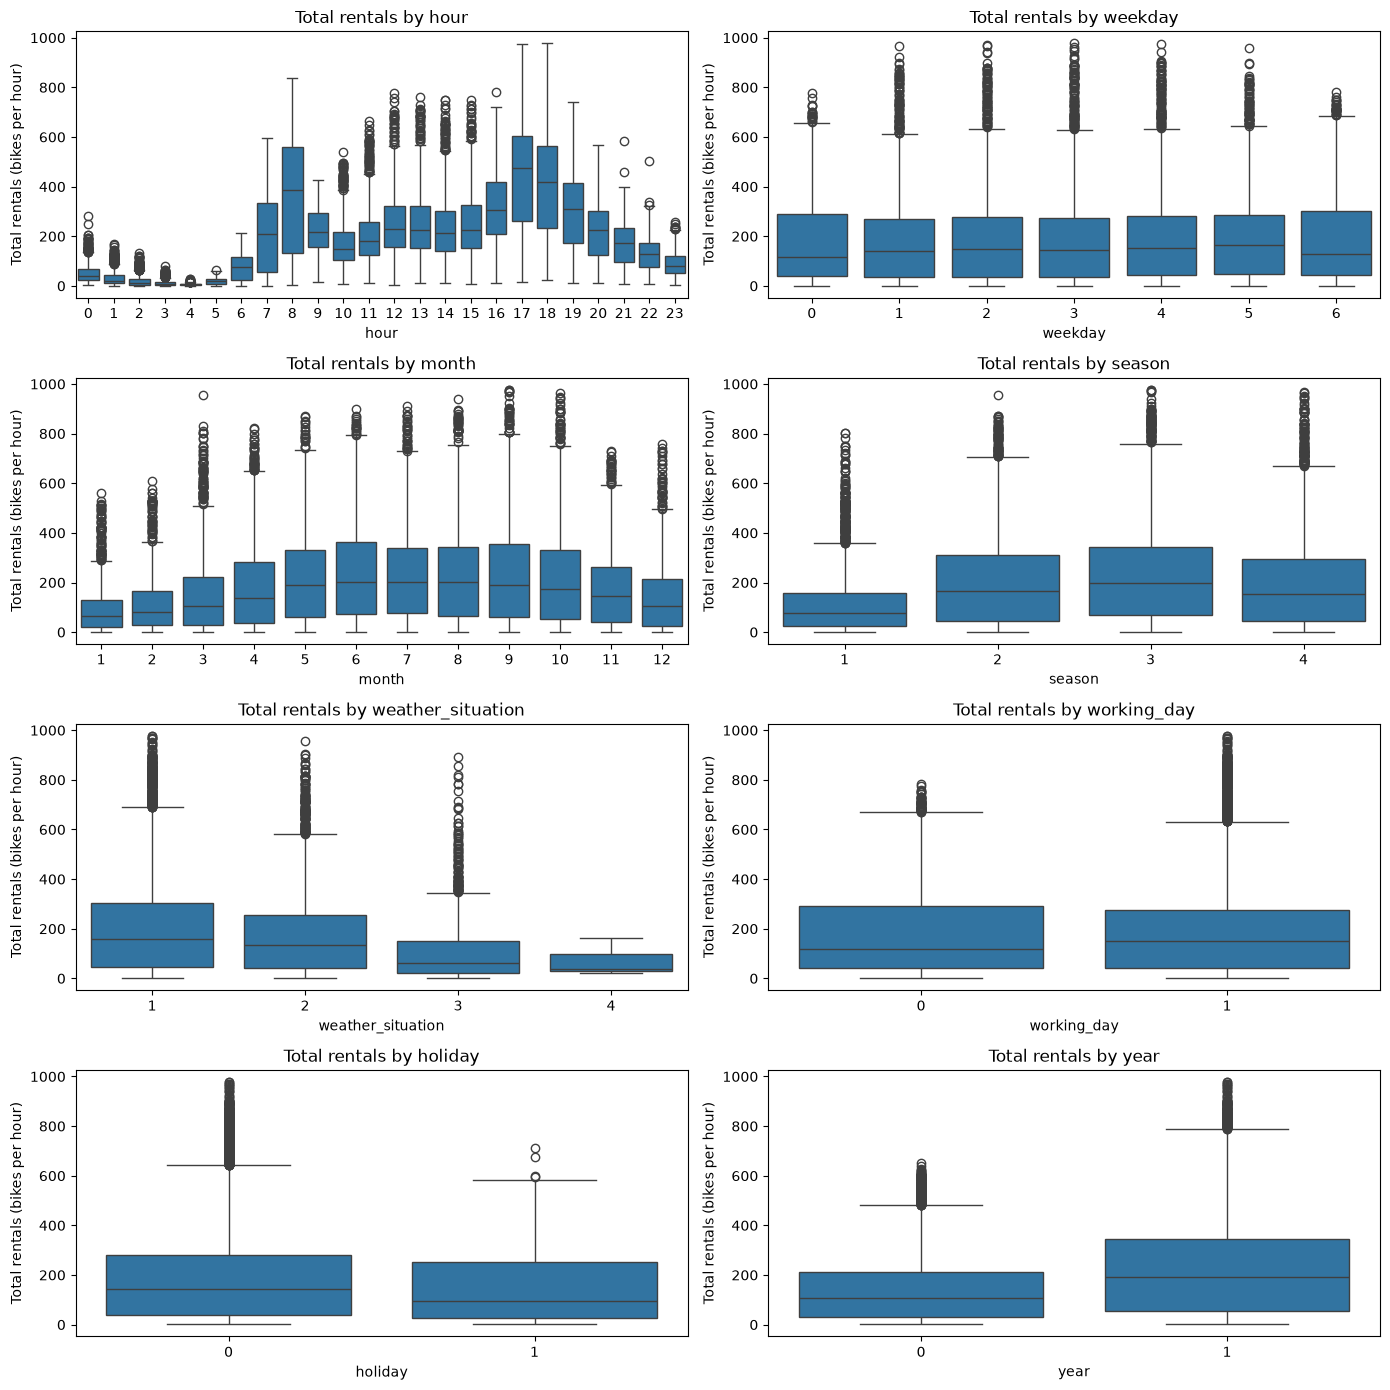

In [372]:
# Target by each categorical column
plot_target_grid(df_eda, BIVARIATE_CATEGORICAL_COLUMNS, sns.boxplot)

**Findings:** `hour` is the strongest pattern, with peaks at 8h and 17h and almost no rentals at night, while `weekday`, `working_day` and `holiday` shift the medians only slightly. Rentals are lower in winter and with worse `weather_situation` (category 4 has very few rows) and higher in 2012 than in 2011.

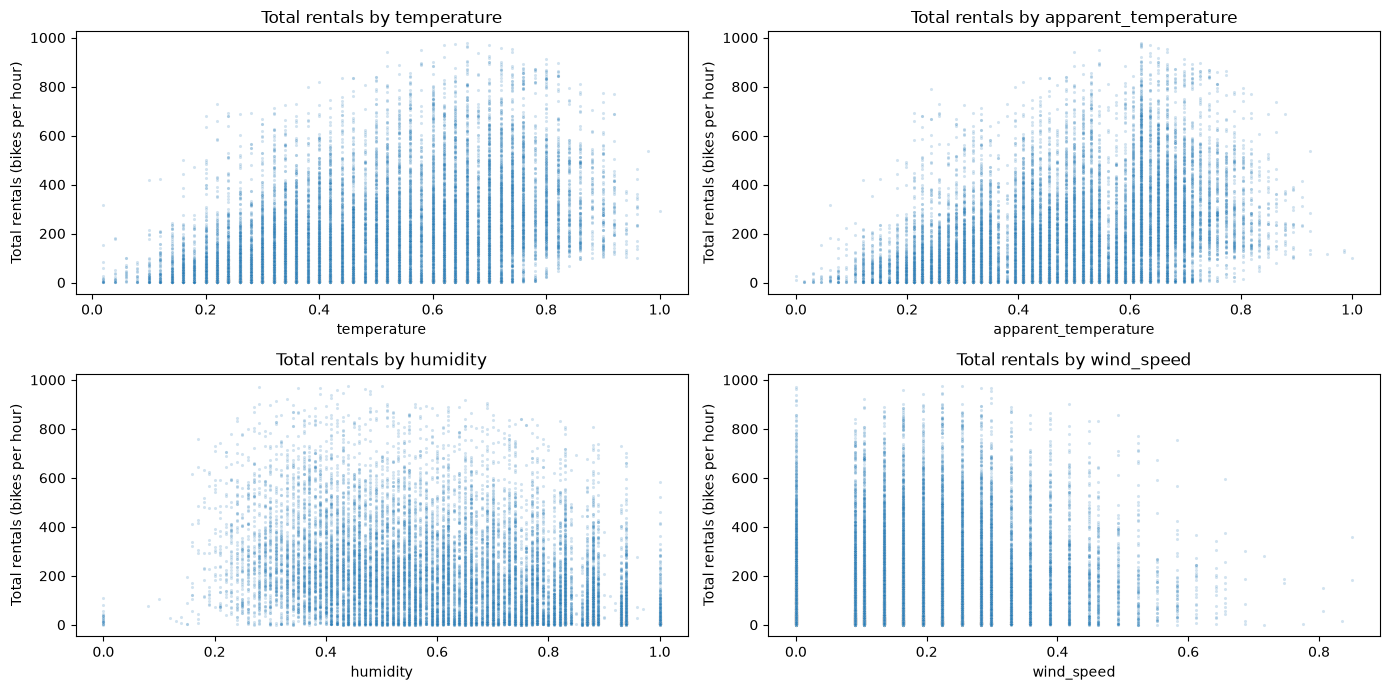

In [373]:
# Target against each continuous column
plot_target_grid(df_eda, BIVARIATE_CONTINUOUS_COLUMNS, sns.scatterplot, s=BIVARIATE_SCATTER_SIZE, alpha=BIVARIATE_SCATTER_ALPHA)

**Findings:** `temperature` and `apparent_temperature` show rentals rising up to about 0.7 on the normalized scale and falling at the hottest end, so the relation is not linear. `humidity` and `wind_speed` mainly lower the maximum rentals at high values, and the wide spread at every x shows that weather alone explains little compared with `hour`.

### 3.4 Correlations

Pearson and Spearman coefficients are computed for the continuous columns and for three discrete columns with an order (`hour`, `year` and `weather_situation`). Pearson measures linear association and Spearman measures monotonic association, so a gap between them signals a curved but monotonic relation. Weak values in both can still hide a non-monotonic pattern, such as the daily cycle of `hour`. Strong correlation between predictors is also checked, since it makes the coefficients of linear models unstable.

In [374]:
# Draws the correlation heatmaps of the given methods side by side
def plot_correlation_heatmaps(df, methods=CORRELATION_METHODS, titles=CORRELATION_TITLES, width=HEATMAP_WIDTH, height=HEATMAP_HEIGHT, colormap=HEATMAP_COLORMAP, limits=HEATMAP_LIMITS, number_format=HEATMAP_NUMBER_FORMAT, annotation_size=HEATMAP_ANNOTATION_SIZE):
    fig, axes = plt.subplots(1, len(methods), figsize=(width, height))
    for ax, method in zip(axes, methods):
        sns.heatmap(df.corr(method=method), annot=True, fmt=number_format, annot_kws={"size": annotation_size}, cmap=colormap, vmin=limits[0], vmax=limits[1], ax=ax)
        ax.set_title(titles[method])
    fig.tight_layout()
    plt.show()

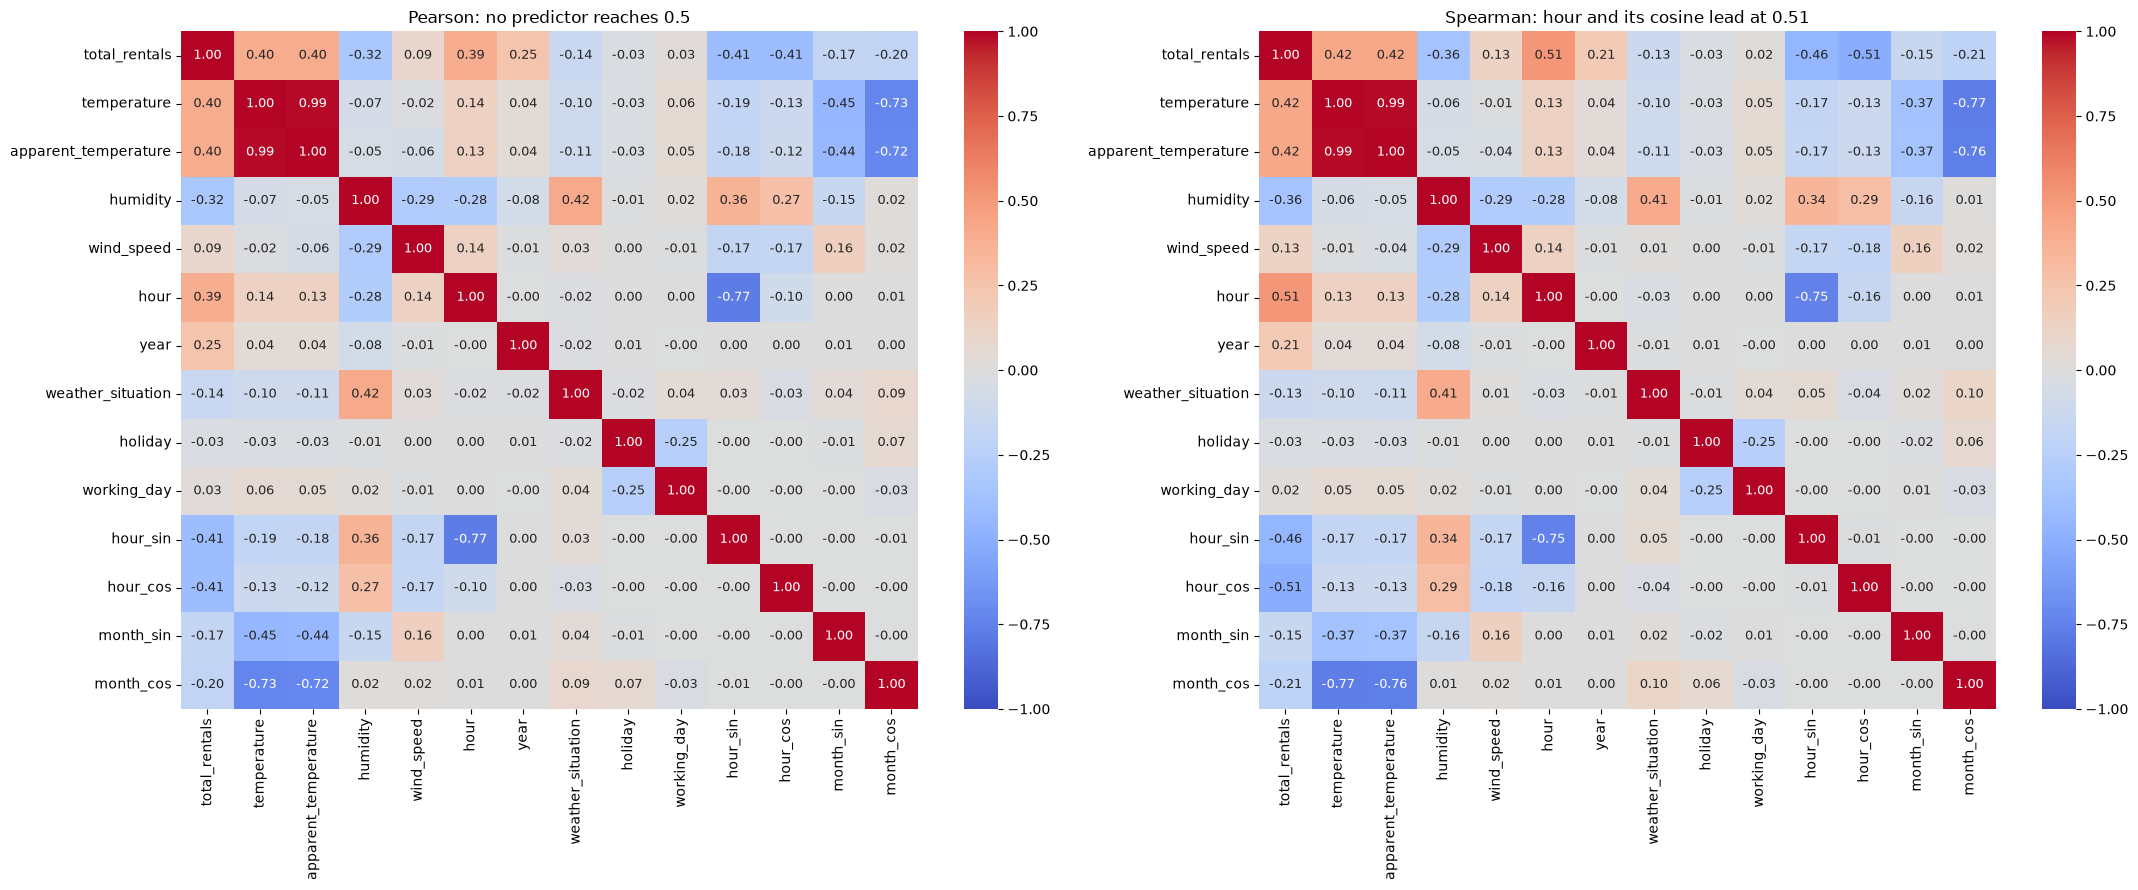

In [375]:
# Pearson and Spearman correlations
plot_correlation_heatmaps(df_eda[CORRELATION_COLUMNS])

**Findings:** Time of day is the strongest signal (`hour` and `hour_cos` at 0.51 in absolute Spearman value, `hour_sin` at -0.46), followed by `temperature` and `apparent_temperature` (0.42) and `humidity` (-0.36), while `holiday` and `working_day` are close to 0. Collinearity is high between `temperature` and `apparent_temperature` (0.99) and between both and `month_cos` (-0.72 to -0.77), which carries the seasonal cycle of temperature.

### 3.5 Hypothesis tests

Three hypotheses are tested on `total_rentals`. Each one has a normality check, a test chosen from it, the p-value, an effect size and a plain conclusion, at a significance level of 0.05.

| Hypothesis | Null hypothesis (H0)                                             | Test                 | Effect size               |
|------------|------------------------------------------------------------------|----------------------|---------------------------|
| H1         | Rentals have the same distribution on working and other days     | Mann-Whitney U       | rank-biserial correlation |
| H2         | Rentals have the same distribution in all four seasons           | Kruskal-Wallis H     | eta squared of H          |
| H3         | Rentals have no monotonic association with temperature           | Spearman correlation | Spearman rho              |

Normality is checked with the D'Agostino-Pearson test, because the Shapiro-Wilk test is not reliable above 5000 rows. With 17,379 rows any test rejects normality for tiny deviations, so the right skew found in 3.2 (1.28 for `total_rentals`) also guides the choice of non-parametric tests, which do not assume normality.

Observations are hourly and neighboring hours are correlated, so the independence assumption is not met and the p-values are optimistic. The effect sizes are the more reliable reading. A common scale for the rank-biserial correlation and Spearman rho is 0.1 small, 0.3 medium and 0.5 large, and for eta squared it is 0.01, 0.06 and 0.14.

In [376]:
# Returns the p-value of the D'Agostino-Pearson normality test
def normality_p_value(values):
    return stats.normaltest(values).pvalue

# Builds a table with the normality p-value of each sample and whether normality holds
def build_normality_table(samples, alpha=ALPHA, index_names=NORMALITY_INDEX_NAMES, columns=NORMALITY_COLUMNS):
    table = pd.concat(samples, names=index_names).to_frame(columns[0])
    table[columns[1]] = table[columns[0]] >= alpha
    return table

# Mann-Whitney U test between two groups, with the rank-biserial correlation as effect size
def mann_whitney_test(first, second):
    result = stats.mannwhitneyu(first, second)
    return result.statistic, result.pvalue, 2*result.statistic/(len(first)*len(second))-1

# Kruskal-Wallis H test across groups, with eta squared of H as effect size
def kruskal_test(groups):
    result = stats.kruskal(*groups)
    total, count = sum(len(group) for group in groups), len(groups)
    return result.statistic, result.pvalue, (result.statistic-count+1)/(total-count)

# Spearman correlation test between two samples, with rho as effect size
def spearman_test(first, second):
    result = stats.spearmanr(first, second)
    return result.statistic, result.pvalue, result.statistic

# Builds one row of the results table from a test outcome
def build_result_row(column, outcome, hypotheses=HYPOTHESES, tests=TESTS, alpha=ALPHA):
    statistic, p_value, effect_size = outcome
    test, effect_measure = tests[column]
    return (hypotheses[column], test, effect_measure, statistic, p_value, effect_size, p_value < alpha)

In [377]:
# Normality of the target in each group and of the target and temperature
normality = build_normality_table({
    WORKING_DAY_COLUMN: df_eda.groupby(WORKING_DAY_COLUMN)[TARGET_COLUMN].apply(normality_p_value),
    SEASON_COLUMN: df_eda.groupby(SEASON_COLUMN)[TARGET_COLUMN].apply(normality_p_value),
    TEMPERATURE_COLUMN: df_eda[[TARGET_COLUMN, TEMPERATURE_COLUMN]].apply(normality_p_value),
})
normality

p_value  is_normal
hypothesis_column sample                                 
working_day       0              4.491258e-158      False
                  1               0.000000e+00      False
season            1               0.000000e+00      False
                  2              1.198688e-128      False
                  3              4.202415e-125      False
                  4              2.799744e-179      False
temperature       total_rentals   0.000000e+00      False
                  temperature     0.000000e+00      False

**Findings:** Normality is rejected (p below 1e-100) for `total_rentals` in every group and for `temperature`, so the non-parametric tests are justified.

In [378]:
# Runs the three tests and collects their results
target_by_working_day = [values for _, values in df_eda.groupby(WORKING_DAY_COLUMN)[TARGET_COLUMN]]
target_by_season = [values for _, values in df_eda.groupby(SEASON_COLUMN)[TARGET_COLUMN]]
results = pd.DataFrame([
    build_result_row(WORKING_DAY_COLUMN, mann_whitney_test(*target_by_working_day)),
    build_result_row(SEASON_COLUMN, kruskal_test(target_by_season)),
    build_result_row(TEMPERATURE_COLUMN, spearman_test(df_eda[TEMPERATURE_COLUMN], df_eda[TARGET_COLUMN])),
], columns=RESULT_COLUMNS)
results

,hypothesis,test,effect_measure,statistic,p_value,effect_size,reject_h0
0,Rentals differ between working and non-working...,Mann-Whitney U,rank-biserial correlation,3.185830e+07,5.558471e-03,-0.026092,True
1,Rentals differ across seasons,Kruskal-Wallis H,eta squared of H,1.190269e+03,9.474683e-258,0.068332,True
2,Rentals are associated with temperature,Spearman correlation,Spearman rho,4.233295e-01,0.000000e+00,0.423330,True


**Findings:** H1 is rejected (p = 0.006) but the effect is negligible (rank-biserial -0.03, working days slightly higher), and with correlated hourly data this p-value is fragile. H2 is rejected (p below 1e-250) with a medium effect (eta squared 0.07), so the season matters. H3 is rejected (p practically zero) with a medium effect (rho 0.42, the same as in 3.4), so warmer hours tend to have more rentals.

### 3.6 Summary

| Finding                                                                        | Consequence for modeling                                           |
|--------------------------------------------------------------------------------|--------------------------------------------------------------------|
| `total_rentals` is right skewed with a heavy upper tail of real peak hours     | Test a log transform of the target and keep the flagged peak hours |
| `hour` has two daily peaks and is the strongest signal                         | Use `hour_sin` and `hour_cos` in linear models and `hour` in trees |
| Rentals rise with temperature then fall, and humidity and wind lower the peaks | Nonlinear models are expected to beat linear ones                  |
| `season` and `year` matter, `working_day` and `holiday` matter little          | Keep `season` and `year`, expect little gain from the other two    |
| `temperature`, `apparent_temperature` and `month_cos` are strongly correlated  | Keep one of the temperatures or use Ridge or Lasso                 |
| Hourly observations are correlated with their neighbors                        | Compare a random split with a temporal split before choosing one   |